# Cosmo Dental Assistant — RAG experiments

This notebook measures and tunes the assistant's RAG pipeline. It answers three questions:

1. **Chunk size:** which chunk size (500 / 800 / 1200 characters) helps retrieval find the right page?
2. **TOP_K and MIN_SCORE:** how many chunks to retrieve, and what similarity score separates "the documents can answer this" from "out of scope"?
3. **End to end:** does the tuned configuration give more correct answers than the default (800 chars, TOP_K 5, MIN_SCORE 0.45)?

**How it works:** the notebook uploads the PDFs from `experiments/docs/` into separate **experiment namespaces** (`exp-c500`, `exp-c800`, `exp-c1200`) in the same Vectorize index. The live assistant only searches the `live` namespace, so patients never see experiment data.

**Cost:** steps 1–2 only embed the questions, so they cost very little. Step 3 calls the LLM. Workers AI gives **10,000 Neurons/day free**; on the free plan, going over the limit makes requests fail instead of billing. The notebook prints an estimate before step 3 and saves partial results if the limit is reached.

## 0. Setup
Create `experiments/.env` from `.env.example` (your Worker URL and admin token), then run the cells in order.

In [1]:
import json, math, os, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv
from pypdf import PdfReader

HERE = Path.cwd() if (Path.cwd() / "experiments.ipynb").exists() else Path.cwd() / "experiments"
load_dotenv(HERE / ".env")
WORKER_URL = os.environ.get("WORKER_URL", "").rstrip("/")
ADMIN_TOKEN = os.environ.get("ADMIN_TOKEN", "")
assert WORKER_URL and ADMIN_TOKEN, "Set WORKER_URL and ADMIN_TOKEN in experiments/.env"

DOCS_DIR = HERE / "docs"
RESULTS_DIR = HERE / "results"
RESULTS_DIR.mkdir(exist_ok=True)
QUESTIONS_FILE = HERE.parent / "eval" / "questions.json"

session = requests.Session()
session.headers.update({"Authorization": f"Bearer {ADMIN_TOKEN}", "Content-Type": "application/json"})

class DailyLimitReached(Exception):
    pass

def api(method, path, body=None, retries=3):
    """Call the Worker admin API. Retries briefly on rate limits; stops on the daily AI limit."""
    for attempt in range(retries + 1):
        r = session.request(method, WORKER_URL + path, data=json.dumps(body) if body is not None else None, timeout=60)
        if r.status_code == 503:
            raise DailyLimitReached(r.json().get("error", "Daily AI limit reached"))
        if r.status_code == 429 and attempt < retries:
            time.sleep(10 * (attempt + 1))
            continue
        if not r.ok:
            raise RuntimeError(f"{method} {path} → {r.status_code}: {r.text[:200]}")
        return r.json()

print("Worker:", WORKER_URL, "| health:", requests.get(WORKER_URL + "/api/health", timeout=30).json())

Worker: https://cosmodental-assistant.b-abozor.workers.dev | health: {'ok': True}


### Chart style
Same three colors everywhere, in a fixed order: blue = first series, orange = second, aqua = third. Text and axes stay neutral.

In [2]:
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]          # categorical slots 1–3 (validated palette)
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.grid.axis": "y", "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "legend.frameon": False,
})

## 1. Experiment settings
Change these to try other ideas. Overlap is kept at about 20% of the chunk size so each size gets the same proportion of overlap.

In [3]:
CHUNK_SIZES = {500: 100, 800: 150, 1200: 240}   # chunk size → overlap (characters)
TOP_KS = [1, 3, 5, 8]                           # evaluated from a single top-8 query per question
BASELINE = {"chunk": 800, "top_k": 5, "min_score": 0.45}   # current wrangler.jsonc settings
NEURONS_PER_ANSWER = 50                         # conservative; Llama 3.1 8B fast is ~10–50 by per-token price. Check the dashboard
FORCE_REINDEX = False                           # True = delete and re-upload the experiment namespaces

## 2. Test questions
`eval/questions.json` holds the questions with:
- `expect`: words a correct answer must contain
- `answerable`: `false` for out-of-scope questions, where the right behaviour is to refuse
- `source_file` / `source_page`: where the answer is, used to score retrieval (`source_page` can be a list when the answer appears on several pages)

**Aim for ~30 questions** about your real clinic PDFs, including **~8 out-of-scope ones**. With fewer, the numbers are noisy.

In [4]:
questions = pd.DataFrame(json.loads(QUESTIONS_FILE.read_text(encoding="utf-8")))
for col, default in [("source_file", None), ("source_page", None)]:
    if col not in questions:
        questions[col] = default
print(f"{len(questions)} questions · {questions.answerable.sum()} answerable · {(~questions.answerable).sum()} out of scope")
questions[["q", "lang", "answerable", "source_file", "source_page"]]

38 questions · 30 answerable · 8 out of scope


,q,lang,answerable,source_file,source_page
0,What is the address of the clinic?,en,True,cosmo-dental-clinic-faq.pdf,"[1, 2]"
1,What are your hours on Saturday?,en,True,cosmo-dental-clinic-faq.pdf,"[1, 2]"
2,Are you open on Sunday?,en,True,cosmo-dental-clinic-faq.pdf,"[1, 2]"
3,What is the clinic's email address?,en,True,cosmo-dental-clinic-faq.pdf,[1]
4,What languages does your team speak?,en,True,cosmo-dental-clinic-faq.pdf,"[1, 2, 11]"
5,Are you accepting new patients?,en,True,cosmo-dental-clinic-faq.pdf,[2]
6,What should I bring to my first visit?,en,True,cosmo-dental-clinic-faq.pdf,[3]
7,How do I cancel my appointment?,en,True,cosmo-dental-clinic-faq.pdf,[3]
8,Which dentist does root canals?,en,True,cosmo-dental-clinic-faq.pdf,"[4, 7]"
9,Who can do my dental implant?,en,True,cosmo-dental-clinic-faq.pdf,"[4, 7]"


## 3. Read the PDFs
Put clinic PDFs (no patient records) in `experiments/docs/`. Each PDF's title is its file name.

In [5]:
import re
from collections import Counter

def read_pdf(path):
    """PDF → [{page, text}], dropping headers/footers that repeat on at least half the pages
    (same rule as the browser admin page, so experiments match production)."""
    pages = [(i + 1, (p.extract_text() or "").strip()) for i, p in enumerate(PdfReader(path).pages)]
    key = lambda line: re.sub(r"\d+", "#", line.strip())
    if len(pages) >= 3:
        counts = Counter(k for _, t in pages for k in {key(l) for l in t.splitlines() if l.strip()})
        repeated = {k for k, n in counts.items() if n / len(pages) >= 0.5}
        pages = [(n, "\n".join(l for l in t.splitlines() if key(l) not in repeated)) for n, t in pages]
    return [{"page": n, "text": t} for n, t in pages if t.strip()]

pdfs = sorted(DOCS_DIR.glob("*.pdf"))
assert pdfs, f"No PDFs in {DOCS_DIR}"
docs = {p.stem: read_pdf(p) for p in pdfs}
pd.DataFrame([{"document": k, "pages": len(v), "characters": sum(len(x["text"]) for x in v)} for k, v in docs.items()])

,document,pages,characters
0,cosmo-dental-clinic-faq,11,23747


## 4. Upload each chunk-size variant into its own experiment namespace

In [6]:
def namespace(size):
    return f"exp-c{size}"

def index_variant(size, overlap):
    ns = namespace(size)
    existing = api("GET", f"/api/admin/documents?namespace={ns}")["documents"]
    if existing and not FORCE_REINDEX and {d["title"] for d in existing} == set(docs):
        return {"namespace": ns, "chunks": sum(d["chunk_count"] for d in existing), "status": "already indexed"}
    if existing:
        api("DELETE", f"/api/admin/namespaces/{ns}")
    total = 0
    for title, pages in docs.items():
        doc_id = api("POST", "/api/admin/documents", {
            "title": title, "filename": f"{title}.pdf", "lang": "en", "pages": len(pages),
            "namespace": ns, "chunkMax": size, "chunkOverlap": overlap,
        })["id"]
        for i in range(0, len(pages), 5):
            total += api("POST", f"/api/admin/documents/{doc_id}/pages", {"pages": pages[i:i + 5]})["added"]
    return {"namespace": ns, "chunks": total, "status": "indexed"}

index_table = pd.DataFrame([{"chunk size": s, **index_variant(s, o)} for s, o in CHUNK_SIZES.items()])
index_table

,chunk size,namespace,chunks,status
0,500,exp-c500,64,already indexed
1,800,exp-c800,40,already indexed
2,1200,exp-c1200,27,already indexed


### Wait until the new chunks are searchable
Vectorize indexes new vectors in the background, so a query right after an upload can find nothing. Run 2 of this experiment
measured that by accident: answers were refused because the index was still filling up. This cell polls each namespace with
5 test questions until every one returns a full top 8 from the new chunks (or gives up after 10 minutes).

In [7]:
probes = list(questions[questions.answerable].q.iloc[::6][:5])   # 5 questions spread across the document
deadline = time.time() + 600
for size in CHUNK_SIZES:
    ns = namespace(size)
    chunks = int(index_table.loc[index_table["chunk size"] == size, "chunks"].iloc[0])
    want = min(8, chunks)
    while True:
        found = min(len(api("POST", "/api/admin/ask", {"question": p, "namespace": ns, "topK": 8, "retrieveOnly": True})["candidates"])
                    for p in probes)
        if found >= want:
            print(f"{ns}: ready ({found}/{want} results)")
            break
        if time.time() > deadline:
            raise RuntimeError(f"{ns} still not searchable after 10 minutes ({found}/{want}). Try again later.")
        print(f"{ns}: indexing… ({found}/{want}) — checking again in 20 s")
        time.sleep(20)

exp-c500: ready (8/8 results)
exp-c800: ready (8/8 results)
exp-c1200: ready (8/8 results)


## 5. Retrieval experiment (cheap: no LLM calls)
For each chunk size we ask every question once (top 8, no score filter) and record:
- **Hit@k:** is the expected page among the first *k* results?
- **MRR (mean reciprocal rank):** 1 if the right page is ranked first, ½ if second, and so on. Higher is better.
- **Top score:** similarity of the best match, used in step 6 to choose MIN_SCORE.

In [8]:
MAX_K = max(TOP_KS)
rows = []
for size in CHUNK_SIZES:
    for q in questions.itertuples():
        r = api("POST", "/api/admin/ask", {"question": q.q, "lang": q.lang, "namespace": namespace(size),
                                            "topK": MAX_K, "retrieveOnly": True})
        cands = r["candidates"]
        rank = None
        if q.answerable and isinstance(q.source_file, str):
            # source_page can be one page, a list of pages, or empty (= any page of that file)
            sp = q.source_page
            ok_pages = None if sp is None or (isinstance(sp, float) and math.isnan(sp)) else \
                {int(x) for x in (sp if isinstance(sp, list) else [sp])}
            for i, c in enumerate(cands, 1):
                if c["title"] == Path(q.source_file).stem and (ok_pages is None or c["page"] in ok_pages):
                    rank = i
                    break
        rows.append({"chunk": size, "q": q.q, "answerable": q.answerable, "rank": rank,
                     "top_score": r["topScore"], "latency_ms": r["latencyMs"]})
retrieval = pd.DataFrame(rows)

scored = retrieval[retrieval.answerable & retrieval.q.isin(questions[questions.source_file.notna()].q)]
summary = scored.groupby("chunk").apply(lambda g: pd.Series({
    **{f"hit@{k}": (g["rank"].fillna(99) <= k).mean() for k in TOP_KS},
    "MRR": g["rank"].map(lambda r: 0 if pd.isna(r) else 1 / r).mean(),
}), include_groups=False)
summary.style.format("{:.0%}", subset=[f"hit@{k}" for k in TOP_KS]).format("{:.2f}", subset=["MRR"])

,hit@1,hit@3,hit@5,hit@8,MRR
chunk,,,,,
500,83%,93%,100%,100%,0.89
800,77%,97%,97%,97%,0.86
1200,67%,90%,93%,93%,0.78


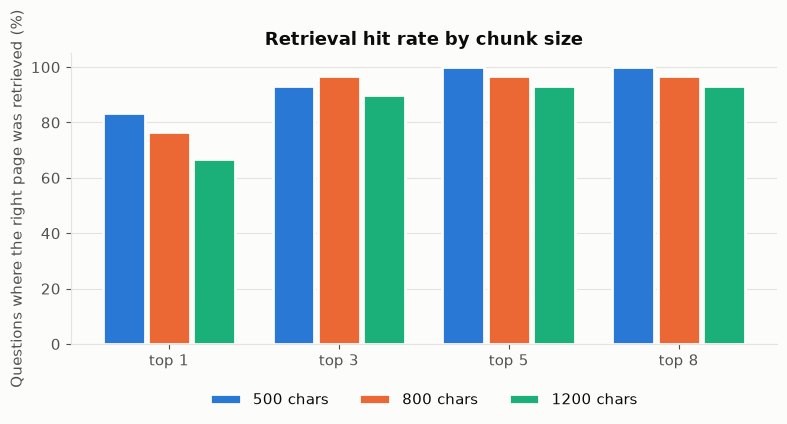

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))
width = 0.8 / len(CHUNK_SIZES)
x = np.arange(len(TOP_KS))
for i, size in enumerate(CHUNK_SIZES):
    vals = [summary.loc[size, f"hit@{k}"] * 100 for k in TOP_KS]
    bars = ax.bar(x + (i - (len(CHUNK_SIZES) - 1) / 2) * width, vals, width - 0.02,
                  color=SERIES[i], label=f"{size} chars", edgecolor=SURFACE, linewidth=2)
ax.set_xticks(x, [f"top {k}" for k in TOP_KS])
ax.set_ylim(0, 105)
ax.set_ylabel("Questions where the right page was retrieved (%)")
ax.set_title("Retrieval hit rate by chunk size")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=len(CHUNK_SIZES))
fig.tight_layout()
fig.savefig(RESULTS_DIR / "retrieval_hit_rate.png", dpi=160)
plt.show()

## 6. Choosing MIN_SCORE
MIN_SCORE works like a gate. Questions whose best match scores below it get "please call the clinic" without an LLM call. A good gate lets answerable questions through and stops out-of-scope ones. We sweep thresholds and pick the middle of the best range, which leaves the most margin on both sides.

Best chunk size (by MRR): 500
Gate accuracy 97% for MIN_SCORE between 0.49 and 0.50 → choose 0.5


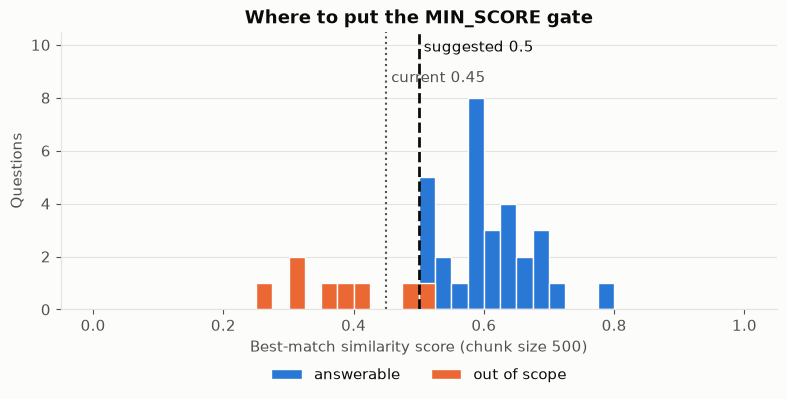

In [10]:
# Highest MRR wins; on a tie keep the current chunk size (no reason to change)
top = summary.index[np.isclose(summary["MRR"], summary["MRR"].max())]
BEST_CHUNK = BASELINE["chunk"] if BASELINE["chunk"] in top else int(top[0])
sub = retrieval[retrieval.chunk == BEST_CHUNK]
thresholds = np.round(np.arange(0.0, 1.0, 0.01), 2)
gate = pd.DataFrame({"threshold": thresholds, "gate_accuracy": [
    ((sub.answerable & (sub.top_score >= t)) | (~sub.answerable & (sub.top_score < t))).mean() for t in thresholds]})
best_acc = gate.gate_accuracy.max()
best_range = gate[gate.gate_accuracy == best_acc].threshold
BEST_MIN_SCORE = float(np.round(best_range.median(), 2))
print(f"Best chunk size (by MRR): {BEST_CHUNK}")
print(f"Gate accuracy {best_acc:.0%} for MIN_SCORE between {best_range.min():.2f} and {best_range.max():.2f} → choose {BEST_MIN_SCORE}")
if BEST_MIN_SCORE < 0.2:
    print("⚠ Very low threshold: out-of-scope questions score as high as answerable ones. Add more test questions, "
          "or rely on the LLM's NO_ANSWER rule instead of the gate.")
if (~sub.answerable).sum() < 5:
    print("⚠ Fewer than 5 out-of-scope questions: add more before trusting this threshold.")

fig, ax = plt.subplots(figsize=(8, 4.2))
bins = np.linspace(0, 1, 41)
ax.hist(sub[sub.answerable].top_score, bins=bins, color=SERIES[0], label="answerable", edgecolor=SURFACE, linewidth=1)
ax.hist(sub[~sub.answerable].top_score, bins=bins, color=SERIES[1], label="out of scope", edgecolor=SURFACE, linewidth=1)
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_ylim(0, ax.get_ylim()[1] * 1.25)          # headroom for the two line labels
ax.axvline(BEST_MIN_SCORE, color=INK, linewidth=2, linestyle="--")
ax.text(BEST_MIN_SCORE, 0.97, f" suggested {BEST_MIN_SCORE}", transform=ax.get_xaxis_transform(), va="top", color=INK)
ax.axvline(BASELINE["min_score"], color=INK_2, linewidth=1.5, linestyle=":")
ax.text(BASELINE["min_score"], 0.86, f" current {BASELINE['min_score']}", transform=ax.get_xaxis_transform(), va="top", color=INK_2)
ax.set_xlabel(f"Best-match similarity score (chunk size {BEST_CHUNK})")
ax.set_ylabel("Questions")
ax.set_title("Where to put the MIN_SCORE gate")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncols=2)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "min_score_gate.png", dpi=160)
plt.show()

In [11]:
# Smallest TOP_K that reaches the best hit rate for the chosen chunk size (fewer chunks = shorter prompt = fewer Neurons)
hit_cols = {k: summary.loc[BEST_CHUNK, f"hit@{k}"] for k in TOP_KS}
BEST_TOP_K = min(k for k, v in hit_cols.items() if v == max(hit_cols.values()))
TUNED = {"chunk": BEST_CHUNK, "top_k": max(BEST_TOP_K, 3), "min_score": BEST_MIN_SCORE}  # keep ≥3 chunks for context
print("Baseline:", BASELINE)
print("Tuned:   ", TUNED)

Baseline: {'chunk': 800, 'top_k': 5, 'min_score': 0.45}
Tuned:    {'chunk': 500, 'top_k': 5, 'min_score': 0.5}


## 7. End-to-end answer quality: baseline vs tuned (uses the LLM)
Each question is answered with both configurations and graded:
- **Correct:** answerable questions must be answered *and* contain every expected word; out-of-scope ones must be refused.
- **Cited:** the answer includes at least one source.

In [12]:
configs = {"baseline": BASELINE, "tuned": TUNED}
estimate = len(questions) * len(configs) * NEURONS_PER_ANSWER
print(f"Rough cost: {estimate:,} Neurons of the 10,000 free per day.")
if estimate > 9000:
    print("⚠ Might hit today's free limit. Partial results are saved; re-run tomorrow to finish.")

Rough cost: 3,800 Neurons of the 10,000 free per day.


In [13]:
def grade(q, r):
    text = (r.get("answer") or "").lower()
    if q.answerable:
        return bool(r.get("answered")) and all(k.lower() in text for k in q.expect)
    return not r.get("answered")

answer_rows = []
try:
    for name, cfg in configs.items():
        for q in questions.itertuples():
            r = api("POST", "/api/admin/ask", {"question": q.q, "lang": q.lang, "namespace": namespace(cfg["chunk"]),
                                                "topK": cfg["top_k"], "minScore": cfg["min_score"]})
            answer_rows.append({"config": name, "q": q.q, "answerable": q.answerable, "answered": r["answered"],
                                "correct": grade(q, r), "cited": bool(r["sources"]), "latency_ms": r["latencyMs"],
                                "answer": r["answer"]})
except DailyLimitReached as e:
    print("Stopped early:", e)

answers = pd.DataFrame(answer_rows)
answers.to_csv(RESULTS_DIR / "answers.csv", index=False)
answers[["config", "q", "correct", "answer"]]

,config,q,correct,answer
0,baseline,What is the address of the clinic?,True,The address of Cosmo Dental Clinic is 159 E No...
1,baseline,What are your hours on Saturday?,True,Cosmo Dental Clinic is open on Saturday from 9...
2,baseline,Are you open on Sunday?,True,"No, Cosmo Dental Clinic is closed on Sunday [1]."
3,baseline,What is the clinic's email address?,True,The clinic email shown on the website is info@...
4,baseline,What languages does your team speak?,True,"Our team speaks English, Spanish, Arabic, Urdu..."
...,...,...,...,...
71,tuned,How do I reset my iPhone password?,True,I couldn't find that in our documents. Please ...
72,tuned,Who won the World Series this year?,True,I couldn't find that in our documents. Please ...
73,tuned,What time does the Walmart in Northlake close?,True,I couldn't find that in our documents. Please ...
74,tuned,Write me a poem about cats.,True,I couldn't find that in our documents. Please ...


In [14]:
def metrics(g):
    a, o = g[g.answerable], g[~g.answerable]
    return pd.Series({
        "accuracy": g.correct.mean(),
        "answered (in scope)": a.answered.mean() if len(a) else np.nan,
        "refused (out of scope)": (~o.answered).mean() if len(o) else np.nan,
        "cited (when answered)": g[g.answered].cited.mean() if g.answered.any() else np.nan,
        "avg latency (ms)": g.latency_ms.mean(),
    })

results = answers.groupby("config").apply(metrics, include_groups=False).reindex(list(configs))
pct_cols = ["accuracy", "answered (in scope)", "refused (out of scope)", "cited (when answered)"]
results.style.format("{:.0%}", subset=pct_cols).format("{:.0f}", subset=["avg latency (ms)"])

,accuracy,answered (in scope),refused (out of scope),cited (when answered),avg latency (ms)
config,,,,,
baseline,97%,100%,100%,100%,552
tuned,97%,100%,100%,100%,503


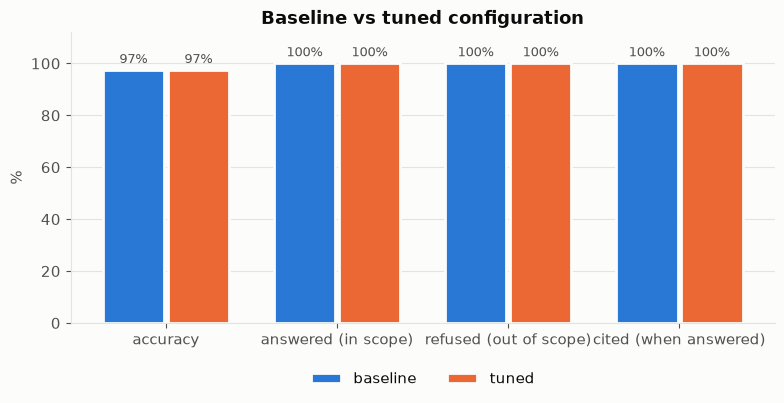

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(pct_cols))
for i, name in enumerate(results.index):
    raw = results.loc[name, pct_cols].astype(float).values * 100
    bars = ax.bar(x + (i - 0.5) * 0.38, np.nan_to_num(raw), 0.36, color=SERIES[i], label=name, edgecolor=SURFACE, linewidth=2)
    ax.bar_label(bars, labels=["n/a" if np.isnan(v) else f"{v:.0f}%" for v in raw], padding=3, color=INK_2, fontsize=9)
ax.set_xticks(x, pct_cols)
ax.set_ylim(0, 112)
ax.set_ylabel("%")
ax.set_title("Baseline vs tuned configuration")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=2)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "baseline_vs_tuned.png", dpi=160)
plt.show()

## 8. Save a summary for the README

In [16]:
stamp = time.strftime("%Y-%m-%d")
retrieval.to_csv(RESULTS_DIR / "retrieval.csv", index=False)
lines = [
    f"## Experiment results ({stamp})", "",
    f"{len(questions)} test questions ({int(questions.answerable.sum())} in scope, {int((~questions.answerable).sum())} out of scope), "
    f"{len(docs)} PDF(s).", "",
    "| Config | Chunk | TOP_K | MIN_SCORE | Accuracy | Refused out-of-scope | Avg latency |",
    "|---|---|---|---|---|---|---|",
]
for name, cfg in configs.items():
    if name in results.index:
        r = results.loc[name]
        lines.append(f"| {name} | {cfg['chunk']} | {cfg['top_k']} | {cfg['min_score']} | {r['accuracy']:.0%} | "
                     f"{'n/a' if pd.isna(r['refused (out of scope)']) else format(r['refused (out of scope)'], '.0%')} | "
                     f"{r['avg latency (ms)']:.0f} ms |")
lines += ["", "![Retrieval hit rate](experiments/results/retrieval_hit_rate.png)",
          "![MIN_SCORE gate](experiments/results/min_score_gate.png)",
          "![Baseline vs tuned](experiments/results/baseline_vs_tuned.png)"]
(RESULTS_DIR / "summary.md").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines))

## Experiment results (2026-10-30)

38 test questions (30 in scope, 8 out of scope), 1 PDF(s).

| Config | Chunk | TOP_K | MIN_SCORE | Accuracy | Refused out-of-scope | Avg latency |
|---|---|---|---|---|---|---|
| baseline | 800 | 5 | 0.45 | 97% | 100% | 552 ms |
| tuned | 500 | 5 | 0.5 | 97% | 100% | 503 ms |

![Retrieval hit rate](experiments/results/retrieval_hit_rate.png)
![MIN_SCORE gate](experiments/results/min_score_gate.png)
![Baseline vs tuned](experiments/results/baseline_vs_tuned.png)


## 9. Apply the winner
If the tuned config wins:
1. In `wrangler.jsonc`, set `TOP_K` and `MIN_SCORE` to the tuned values, then `npm run deploy`.
2. If the best chunk size isn't 800, change `chunkMax`/`chunkOverlap` defaults (`src/index.ts`, `DEFAULT_CHUNK` in `src/chunk.ts`), deploy, then delete and re-upload the live PDFs on the admin page.
3. Paste `results/summary.md` into the README's **Results** section.

## 10. Clean up (optional)
Removes the experiment namespaces. The live assistant is never touched.

In [17]:
CLEAN_UP = False
if CLEAN_UP:
    for size in CHUNK_SIZES:
        print(namespace(size), api("DELETE", f"/api/admin/namespaces/{namespace(size)}"))